# Financial Time Series Models

Companion to [the financial time-series note](../../notes/time_series/financial_time_series_models.md). We compute returns, simulate a GARCH(1,1) process, show why squared returns carry the dependence, verify the long-run variance formula, estimate the parameters by maximum likelihood and add a GJR asymmetry term.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
P0, P1 = 100.0, 102.0
print("log return   :", round(np.log(P1/P0),5))
print("simple return:", P1/P0-1)
rng = np.random.default_rng(5)
logp = np.cumsum(rng.normal(0.0003, 0.01, 500))
price = 100*np.exp(logp)
r = np.diff(np.log(price))
R = price[1:]/price[:-1]-1
print("sum of log returns == log(P_T/P_0):", np.isclose(r.sum(), np.log(price[-1]/price[0])))
print("max |log return - simple return|   :", np.abs(r-R).max().round(5))

log return   : 0.0198
simple return: 0.020000000000000018
sum of log returns == log(P_T/P_0): True
max |log return - simple return|   : 0.0004


Log returns add over time and are close to simple returns when changes are small. Prices wander; returns are the natural modelling target.

h_t = 0.048  sd = 0.219
long-run variance formula: 0.39999999999999963  sample variance: 0.388


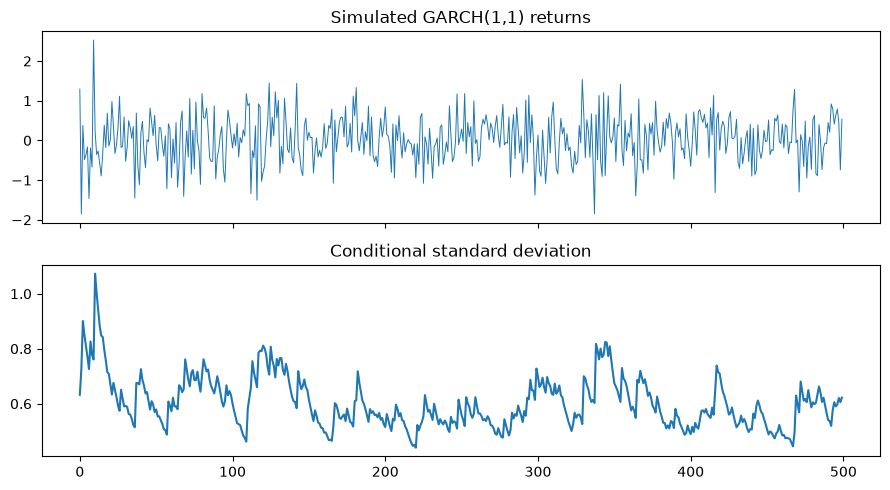

In [2]:
def sim_garch(n, a0, a1, b1, seed, gamma=0.0):
    rg = np.random.default_rng(seed)
    h = np.empty(n); eps = np.empty(n)
    h[0] = a0/(1-a1-b1-gamma/2)
    eps[0] = np.sqrt(h[0])*rg.normal()
    for i in range(1, n):
        h[i] = a0 + a1*eps[i-1]**2 + gamma*(eps[i-1]<0)*eps[i-1]**2 + b1*h[i-1]
        eps[i] = np.sqrt(h[i])*rg.normal()
    return eps, h
# worked example: h_t = 0.01 + 0.10*0.2^2 + 0.85*0.04
print("h_t =", 0.01+0.10*0.2**2+0.85*0.04, " sd =", round(np.sqrt(0.048),3))
a0,a1,b1 = 0.02, 0.10, 0.85
eps, h = sim_garch(4000, a0, a1, b1, seed=3)
print("long-run variance formula:", a0/(1-a1-b1), " sample variance:", eps.var().round(3))
fig,ax = plt.subplots(2,1,figsize=(9,5),sharex=True)
ax[0].plot(eps[:500],lw=.7); ax[0].set_title("Simulated GARCH(1,1) returns")
ax[1].plot(np.sqrt(h[:500])); ax[1].set_title("Conditional standard deviation"); plt.tight_layout(); plt.show()

The sample variance is close to $\alpha_0/(1-\alpha_1-\beta_1)=0.4$ (with persistence $0.95$ convergence is slow). Volatility clusters: calm and turbulent regimes alternate even though the sign of each return is unpredictable.

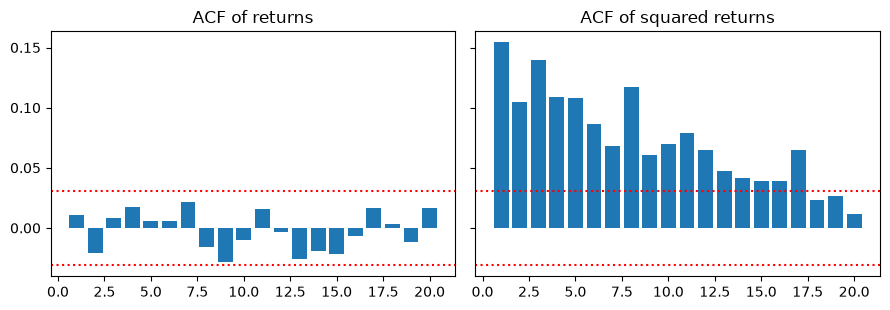

lag-1 ACF returns: 0.011  squared: 0.154


In [3]:
from statsmodels.tsa.stattools import acf
fig,ax = plt.subplots(1,2,figsize=(9,3.2),sharey=True)
for a,v,ttl in [(ax[0],eps,"returns"),(ax[1],eps**2,"squared returns")]:
    a.bar(range(1,21), acf(v,nlags=20)[1:]); a.axhline(1.96/np.sqrt(len(v)),ls=":",c="r"); a.axhline(-1.96/np.sqrt(len(v)),ls=":",c="r")
    a.set_title("ACF of "+ttl)
plt.tight_layout(); plt.show()
print("lag-1 ACF returns:", acf(eps,nlags=1)[1].round(3), " squared:", acf(eps**2,nlags=1)[1].round(3))

Returns are nearly uncorrelated but squared returns are clearly autocorrelated: the diagnostic that motivates conditional-variance models. This is dependence without linear correlation.

In [4]:
from scipy.optimize import minimize
def nll(theta, e):
    w, a, b = theta
    if w<=0 or a<0 or b<0 or a+b>=0.9999: return 1e10
    hh = np.empty(len(e)); hh[0] = e.var()
    for i in range(1,len(e)):
        hh[i] = w + a*e[i-1]**2 + b*hh[i-1]
    return 0.5*np.sum(np.log(2*np.pi*hh) + e**2/hh)
fit = minimize(nll, [0.05,0.05,0.8], args=(eps,), method="Nelder-Mead", options={"xatol":1e-6,"fatol":1e-8,"maxiter":2000})
print("true (a0,a1,b1) =", (a0,a1,b1))
print("MLE  (a0,a1,b1) =", fit.x.round(3), " persistence:", fit.x[1:].sum().round(3))

true (a0,a1,b1) = (0.02, 0.1, 0.85)
MLE  (a0,a1,b1) = [0.028 0.098 0.829]  persistence: 0.927


Gaussian quasi-maximum likelihood recovers the parameters reasonably well from 4000 observations. The persistence $\alpha_1+\beta_1$ is typically the best-identified quantity.

In [5]:
# Asymmetry: GJR term, and a Gaussian VaR backtest
g_eps, g_h = sim_garch(6000, 0.02, 0.05, 0.85, seed=9, gamma=0.10)
after_neg = g_h[1:][g_eps[:-1] < 0].mean(); after_pos = g_h[1:][g_eps[:-1] > 0].mean()
print(f"mean next-step variance after negative shock: {after_neg:.3f}; after positive: {after_pos:.3f}")
z = -2.3263   # 1% quantile
var_line = z*np.sqrt(g_h)
print("1% VaR breach rate (true h):", np.mean(g_eps < var_line).round(4))

mean next-step variance after negative shock: 0.471; after positive: 0.415
1% VaR breach rate (true h): 0.0105


With $\gamma>0$ negative shocks raise next-period variance more than positive shocks of the same size. Using the true conditional variance, the 1% Gaussian quantile is breached about 1% of the time; a miscalibrated variance or fat-tailed innovations would show a different breach rate.